# Bloque 4: Ejercicio 4.4

## Ejercicio 4.4: ¿Cuándo conviene insertion sort?

Para $n = 100$ y $k = 5, 10, 15, 20, 25, 30, 40$, genere 300 listas nuevas por cada $k$. En cada lista defina $Y = 1$ si $C_{100} < Q_{100}$ (insertion sort usa menos comparaciones que quicksort) e $Y = 0$ si no.

---

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as stats
import statsmodels.api as sm
from codigo_base import medir

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.titlesize": 11,
    "lines.linewidth": 2,
    "legend.frameon": False,
    "legend.fontsize": 9,
})
AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#52514e"

rng = np.random.default_rng(4)

### Generación de las listas

Usamos `medir` de `codigo_base.py`, que corre insertion sort y quicksort (pivote en el primer elemento) sobre **las mismas** listas, así cada lista da un par $(C_{100}, Q_{100})$.

In [2]:
ks = [5, 10, 15, 20, 25, 30, 40]
N_k = 300

filas = []
for k in ks:
    filas += medir("insertion_vs_quick", ["insertion", "quick_primero"], n=100, N=N_k, rng=rng, k=k)

# una fila por lista, con C (comparaciones de insertion) y Q (comparaciones de quicksort)
datos = (pd.DataFrame(filas)
         .pivot_table(index=["k", "lista"], columns="algoritmo", values="comparaciones")
         .rename(columns={"insertion": "C", "quick_primero": "Q"})
         .reset_index())
datos["Y"] = (datos["C"] < datos["Q"]).astype(int)

print(f"{len(datos)} listas ({N_k} por cada k)")
print(f"empates C = Q: {(datos['C'] == datos['Q']).sum()} (cuentan como Y = 0)")
datos.head()

2100 listas (300 por cada k)
empates C = Q: 1 (cuentan como Y = 0)


algoritmo,k,lista,C,Q,Y
0,5,0,372.0,2966.0,1
1,5,1,334.0,2594.0,1
2,5,2,506.0,2209.0,1
3,5,3,354.0,2405.0,1
4,5,4,382.0,2288.0,1


---

### 4.4 a)

Grafique la proporción de $Y = 1$ en función de $k$. ¿Por qué insertion sort gana con listas casi ordenadas? Ajuste una regresión lineal de $Y$ en función de $k$: ¿por qué no es un modelo adecuado?

recta: Y = 1.199 + (-0.0342) k
  predicción en k =  0:  1.199
  predicción en k =  5:  1.028
  predicción en k = 35:  0.003
  predicción en k = 40: -0.168
  predicción en k = 50: -0.510


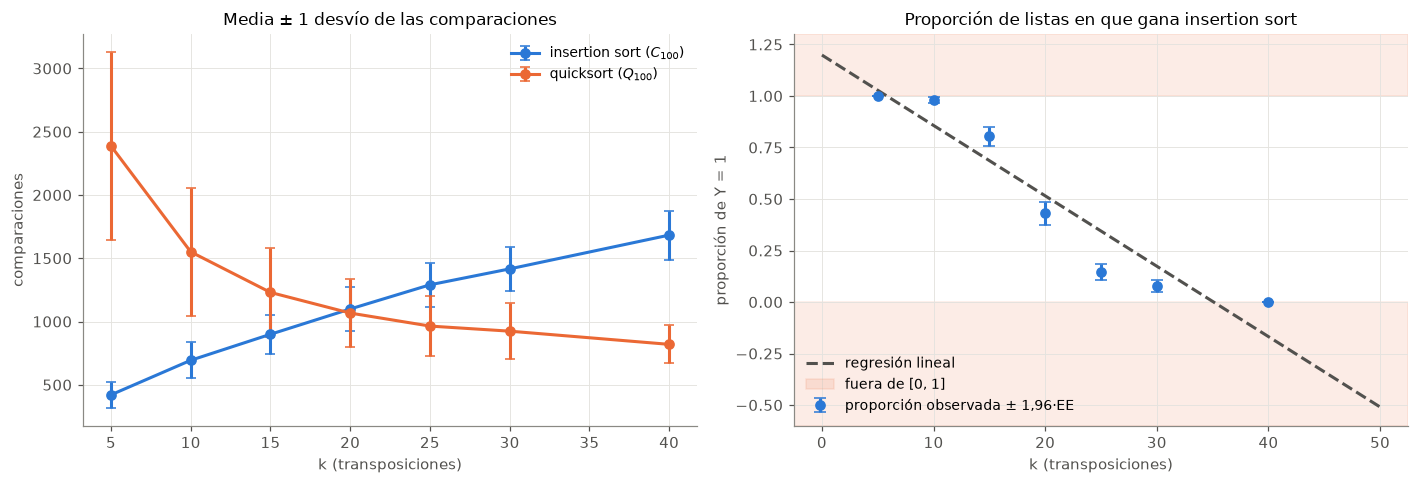

In [3]:
por_k = datos.groupby("k").agg(p=("Y", "mean"), C=("C", "mean"), Q=("Q", "mean"),
                                sC=("C", "std"), sQ=("Q", "std"))
por_k["ee"] = np.sqrt(por_k["p"] * (1 - por_k["p"]) / N_k)

# Regresión lineal de Y en k (cuadrados mínimos)
X = sm.add_constant(datos["k"])
lineal = sm.OLS(datos["Y"], X).fit()
a_lin, b_lin = lineal.params
print(f"recta: Y = {a_lin:.3f} + ({b_lin:.4f}) k")
for k0 in [0, 5, 35, 40, 50]:
    print(f"  predicción en k = {k0:>2}: {a_lin + b_lin * k0:6.3f}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# Izquierda: comparaciones medias de cada algoritmo
ax1.errorbar(por_k.index, por_k["C"], yerr=por_k["sC"], fmt="o-", color=AZUL, capsize=3,
             label="insertion sort ($C_{100}$)")
ax1.errorbar(por_k.index, por_k["Q"], yerr=por_k["sQ"], fmt="o-", color=NARANJA, capsize=3,
             label="quicksort ($Q_{100}$)")
ax1.set_xlabel("k (transposiciones)")
ax1.set_ylabel("comparaciones")
ax1.set_title("Media ± 1 desvío de las comparaciones")
ax1.legend()

# Derecha: proporción de Y = 1 y la recta
ax2.errorbar(por_k.index, por_k["p"], yerr=1.96 * por_k["ee"], fmt="o", color=AZUL, capsize=4,
             label="proporción observada ± 1,96·EE")
grilla = np.linspace(0, 50, 200)
ax2.plot(grilla, a_lin + b_lin * grilla, "--", color=GRIS, label="regresión lineal")
ax2.axhspan(1, 1.3, color=NARANJA, alpha=0.12)
ax2.axhspan(-0.6, 0, color=NARANJA, alpha=0.12, label="fuera de [0, 1]")
ax2.set_ylim(-0.6, 1.3)
ax2.set_xlabel("k (transposiciones)")
ax2.set_ylabel("proporción de Y = 1")
ax2.set_title("Proporción de listas en que gana insertion sort")
ax2.legend(loc="lower left")
plt.tight_layout()
plt.show()

La proporción de listas en las que gana insertion sort es $1$ con $k = 5$, $0{,}98$ con $k = 10$ y $0{,}80$ con $k = 15$, cae a $0{,}43$ con $k = 20$ y después sigue bajando hasta $0$ con $k = 40$. Entre $k = 15$ y $k = 25$ es donde cambia qué algoritmo conviene.

Insertion sort gana con listas casi ordenadas porque sus comparaciones dependen de cuántas inversiones tiene la lista: como vimos en el 3.3 c, $C_{100} = S_{100} + 99 - M$, y $S_{100}$ es la cantidad de inversiones. Una lista casi ordenada tiene pocas inversiones (cada transposición agrega en promedio $(n-1)(2n-1)/(3n) \approx 66$), así que con $k = 5$ insertion sort hace unas $420$ comparaciones, cerca de $99 + 5 \cdot 66$.

Quicksort con pivote en el primer elemento hace lo contrario. En una lista casi ordenada el primer elemento suele ser el mínimo del subarreglo, así que la partición deja todo de un lado y en cada paso se saca un solo elemento, como en la lista ordenada, que es el peor caso ($4950$ comparaciones). Con $k = 5$ hace en promedio $2387$. A medida que $k$ crece la lista se parece a una permutación uniforme, $C_{100}$ sube hacia $\approx 2570$ y $Q_{100}$ baja hacia $647{,}85$, y las medias se cruzan cerca de $k = 20$.

La regresión lineal da $\hat Y = 1{,}199 - 0{,}0342\,k$ y no es un modelo adecuado. Como $Y$ solo vale 0 o 1, lo que se está modelando es $P(Y = 1 \mid k)$, que tiene que estar entre 0 y 1, y la recta se sale de ese rango: predice $1{,}2$ para $k = 0$ y $-0{,}17$ para $k = 40$. Además las proporciones tienen forma de S (planas cerca de 1, una caída fuerte entre 15 y 25 y planas cerca de 0), y una recta no puede seguir esa forma: subestima la proporción en $k = 10$ y $15$ y la sobreestima en $k = 25$ y $30$.

Por otro lado, $\operatorname{Var}(Y \mid k) = \pi(k)(1 - \pi(k))$ cambia con $k$ (es casi 0 en los extremos y máxima cuando $\pi = 0{,}5$), así que no se cumple el supuesto de varianza constante, y los errores solo pueden tomar dos valores para cada $k$, así que tampoco son normales.

---

### 4.4 b)

Ajuste el modelo logístico, con $\pi(k) = P(Y = 1 \mid k)$ y `statsmodels.api.Logit`:
$$\log\frac{\pi(k)}{1 - \pi(k)} = \beta_0 + \beta_1 k.$$
Construya un intervalo de confianza de Wald de nivel 0,95 para $\beta_1$ e interprete $e^{\hat\beta_1}$. Compare las probabilidades ajustadas con las proporciones observadas.

β̂0 = 6.2520   EE = 0.2807   IC Wald 95%: [5.7019, 6.8022]
β̂1 = -0.3172   EE = 0.0138   IC Wald 95%: [-0.3443, -0.2901]
(statsmodels conf_int da lo mismo: [-0.3443, -0.2901])

e^β̂1 = 0.7282   IC 95%: [0.7087, 0.7482]

    observada  ajustada      z
k                             
5       1.000     0.991  1.680
10      0.980     0.956  2.022
15      0.803     0.817 -0.601
20      0.430     0.477 -1.637
25      0.147     0.157 -0.514
30      0.077     0.037  3.659
40      0.000     0.002 -0.694


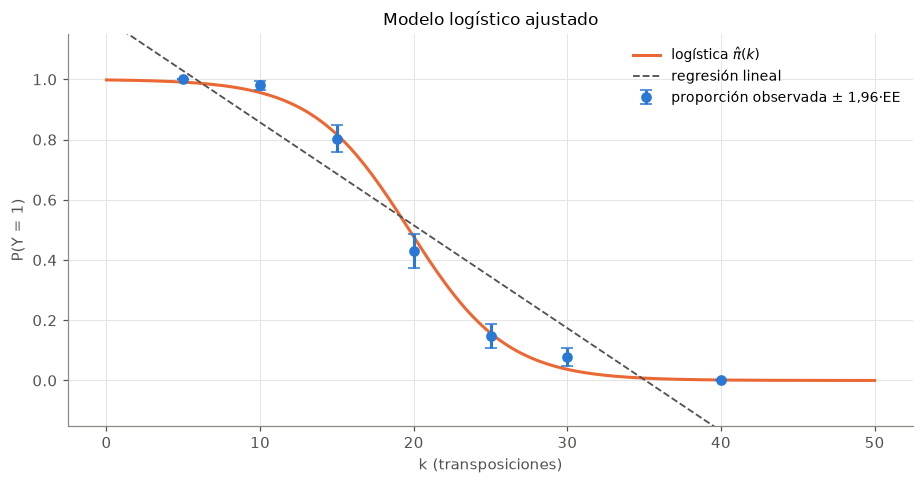

In [4]:
logit = sm.Logit(datos["Y"], X).fit(disp=0)
b0, b1 = logit.params
ee0, ee1 = logit.bse
z975 = stats.norm.ppf(0.975)

print(f"β̂0 = {b0:.4f}   EE = {ee0:.4f}   IC Wald 95%: [{b0 - z975 * ee0:.4f}, {b0 + z975 * ee0:.4f}]")
print(f"β̂1 = {b1:.4f}   EE = {ee1:.4f}   IC Wald 95%: [{b1 - z975 * ee1:.4f}, {b1 + z975 * ee1:.4f}]")
print(f"(statsmodels conf_int da lo mismo: {logit.conf_int().loc['k'].round(4).tolist()})")
print(f"\ne^β̂1 = {np.exp(b1):.4f}   IC 95%: [{np.exp(b1 - z975 * ee1):.4f}, {np.exp(b1 + z975 * ee1):.4f}]")

# Probabilidades ajustadas vs proporciones observadas
por_k["ajustada"] = logit.predict(sm.add_constant(pd.Series(ks, name="k"), has_constant="add")).to_numpy()
por_k["z"] = (por_k["p"] - por_k["ajustada"]) / np.sqrt(por_k["ajustada"] * (1 - por_k["ajustada"]) / N_k)
print()
print(por_k[["p", "ajustada", "z"]].rename(columns={"p": "observada"}).round(3).to_string())

def pi_logit(k):
    return 1 / (1 + np.exp(-(b0 + b1 * k)))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.errorbar(por_k.index, por_k["p"], yerr=1.96 * por_k["ee"], fmt="o", color=AZUL, capsize=4,
            label="proporción observada ± 1,96·EE", zorder=3)
ax.plot(grilla, pi_logit(grilla), color=NARANJA, label=r"logística $\hat\pi(k)$")
ax.plot(grilla, a_lin + b_lin * grilla, "--", color=GRIS, lw=1.2, label="regresión lineal")
ax.set_ylim(-0.15, 1.15)
ax.set_xlabel("k (transposiciones)")
ax.set_ylabel("P(Y = 1)")
ax.set_title("Modelo logístico ajustado")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

El modelo logístico plantea que el logaritmo de las chances $\pi/(1-\pi)$ es una recta en $k$, lo cual hace que $\pi(k) = 1/(1 + e^{-(\beta_0 + \beta_1 k)})$ quede siempre entre 0 y 1 y tenga forma de S. Obtuvimos $\hat\beta_0 = 6{,}25$ y $\hat\beta_1 = -0{,}317$, con error estándar $0{,}0138$.

El intervalo de Wald es $\hat\beta_1 \pm 1{,}96 \cdot \mathrm{EE}(\hat\beta_1)$, que da $[-0{,}344;\ -0{,}290]$. No contiene al 0, así que $k$ tiene efecto sobre la probabilidad de que gane insertion sort, y el efecto es negativo: con más desorden gana menos.

$e^{\hat\beta_1} = 0{,}728$, lo cual significa que cada transposición más multiplica las chances de que gane insertion sort por $0{,}728$, es decir que las baja un $27\%$. Con el intervalo, el factor está entre $0{,}709$ y $0{,}748$. Por ejemplo, 5 transposiciones más multiplican las chances por $0{,}728^5 \approx 0{,}20$. Lo que se multiplica son las chances $\pi/(1-\pi)$ y no la probabilidad, por eso la probabilidad baja poco cuando está cerca de 1 o de 0 y mucho cerca de $0{,}5$.

Las probabilidades ajustadas siguen bien a las observadas: $0{,}991$ contra $1$ en $k = 5$, $0{,}817$ contra $0{,}803$ en $k = 15$, $0{,}477$ contra $0{,}430$ en $k = 20$ y $0{,}157$ contra $0{,}147$ en $k = 25$. Las diferencias más grandes están en $k = 30$, donde el modelo da $0{,}037$ y observamos $0{,}077$ (unos $3{,}7$ errores estándar), y en $k = 10$, donde da $0{,}956$ y observamos $0{,}980$ (unos 2). Igual la logística describe bien la forma general, mucho mejor que la recta.

---

### 4.4 c)

¿Para qué valor de $k$ el modelo estima que los dos algoritmos tienen la misma probabilidad de ganar? Exprese ese valor en función de $\beta_0$ y $\beta_1$, y estímelo.

k* = -β̂0 / β̂1 = -6.2520 / -0.3172 = 19.71
proporción observada en k = 20: 0.430


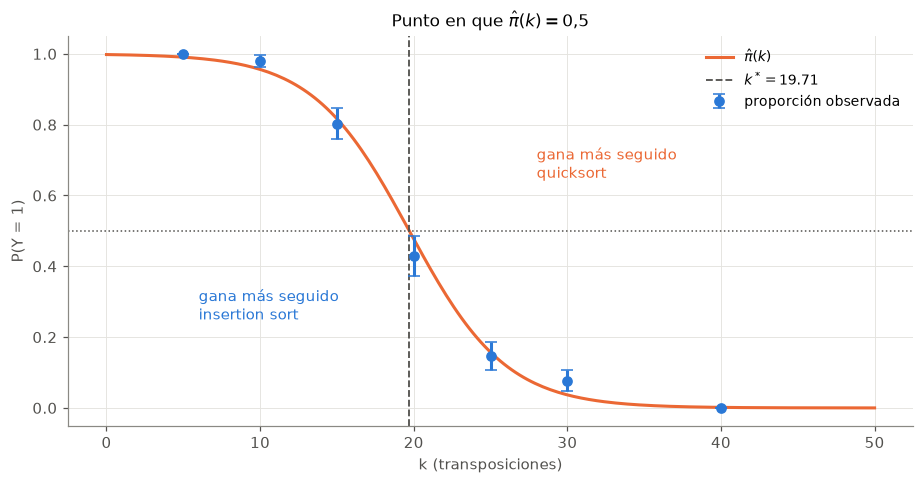

In [5]:
k_star = -b0 / b1
print(f"k* = -β̂0 / β̂1 = {-b0:.4f} / {b1:.4f} = {k_star:.2f}")
print(f"proporción observada en k = 20: {por_k.loc[20, 'p']:.3f}")

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.plot(grilla, pi_logit(grilla), color=NARANJA, label=r"$\hat\pi(k)$")
ax.errorbar(por_k.index, por_k["p"], yerr=1.96 * por_k["ee"], fmt="o", color=AZUL, capsize=4,
            label="proporción observada", zorder=3)
ax.axhline(0.5, color=GRIS, ls=":", lw=1)
ax.axvline(k_star, color=GRIS, ls="--", lw=1.2, label=f"$k^* = {k_star:.2f}$")
ax.annotate("gana más seguido\ninsertion sort", (6, 0.25), color=AZUL)
ax.annotate("gana más seguido\nquicksort", (28, 0.65), color=NARANJA)
ax.set_xlabel("k (transposiciones)")
ax.set_ylabel("P(Y = 1)")
ax.set_title(r"Punto en que $\hat\pi(k) = 0{,}5$")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

Los dos algoritmos tienen la misma probabilidad de ganar cuando $\pi(k) = 0{,}5$, es decir cuando las chances valen 1 y su logaritmo vale 0. Entonces $\beta_0 + \beta_1 k^* = 0$, y
$$k^* = -\frac{\beta_0}{\beta_1}.$$
Con los valores estimados, $k^* = -6{,}252 / (-0{,}3172) \approx 19{,}7$.

Tiene sentido con lo observado: con $k = 15$ gana insertion sort el $80\%$ de las veces y con $k = 20$ el $43\%$, así que el cruce está apenas antes de 20. También coincide con el gráfico del a), donde las comparaciones medias de los dos algoritmos se cruzan cerca de $k = 20$. Lo cual significa que para listas de 100 elementos conviene insertion sort si la lista tiene menos de unas 20 transposiciones, y quicksort con pivote en el primer elemento si tiene más.